# 保存実験データの作図（APS / 300 dpi）
Conda kernel **knill_system** で実行する。登録セルはデータを読まない。
各作図セルの `filter_by`, `group_by` を編集できる。
[APIと定義](../docs/notebook_plotting.md) を参照。
積み上げlifetime図以外は既定で95% Wilson shade付き（低減率はpaired-count由来の保守的な帯）。


In [7]:
from pathlib import Path
from knill_bench.analysis import RunRegistry, NotebookPlots, FigureStyle

root = Path("/home/quantum_teresheys/workspace/knilll_bench/results/cluster/results")
data = RunRegistry({
    "fig4d": root / "20261017224016_27f982ab_fig4d",
    "memory": root / "20261017224951_8501f871_my_se_memory",
    "factory": root / "20261021061441_97825404_logical_zero_factory",
    "ideal_bell": root / "20261022100223_0522ba07_ideal_bell",
    "code_capacity": root / "20261022095055_e051a690_code_capacity",
})
# 添付図に近い共通設定: 6x3.6 inch, 軸ラベル14pt / 目盛13pt / 凡例12pt
style = FigureStyle(dpi=300, labels={
    "Physical error rate": r"$\mathrm{Physical\ Error\ Rate}$",
    # "logical error rate": r"$p_{\mathrm{L}}$",
    # "Logical gap": r"$\mathsf{Logical\ gap}$",
})
# 実際のLaTeXを使う場合: FigureStyle(usetex=True, labels=...)
# 個別調整: style.settings = {"axes.labelsize": 16, "xtick.labelsize": 14}
plots = NotebookPlots(data, style=style, round_digit=0)
# round_digit=None: 丸めなし / 整数: 集計・閾値判定前に四捨五入


## 1. 未選別LER vs 物理エラー率
`per_rounds=True` で rounds（memory）またはT（Knill/factory）あたりに換算。
未完了pointは警告して除外する。


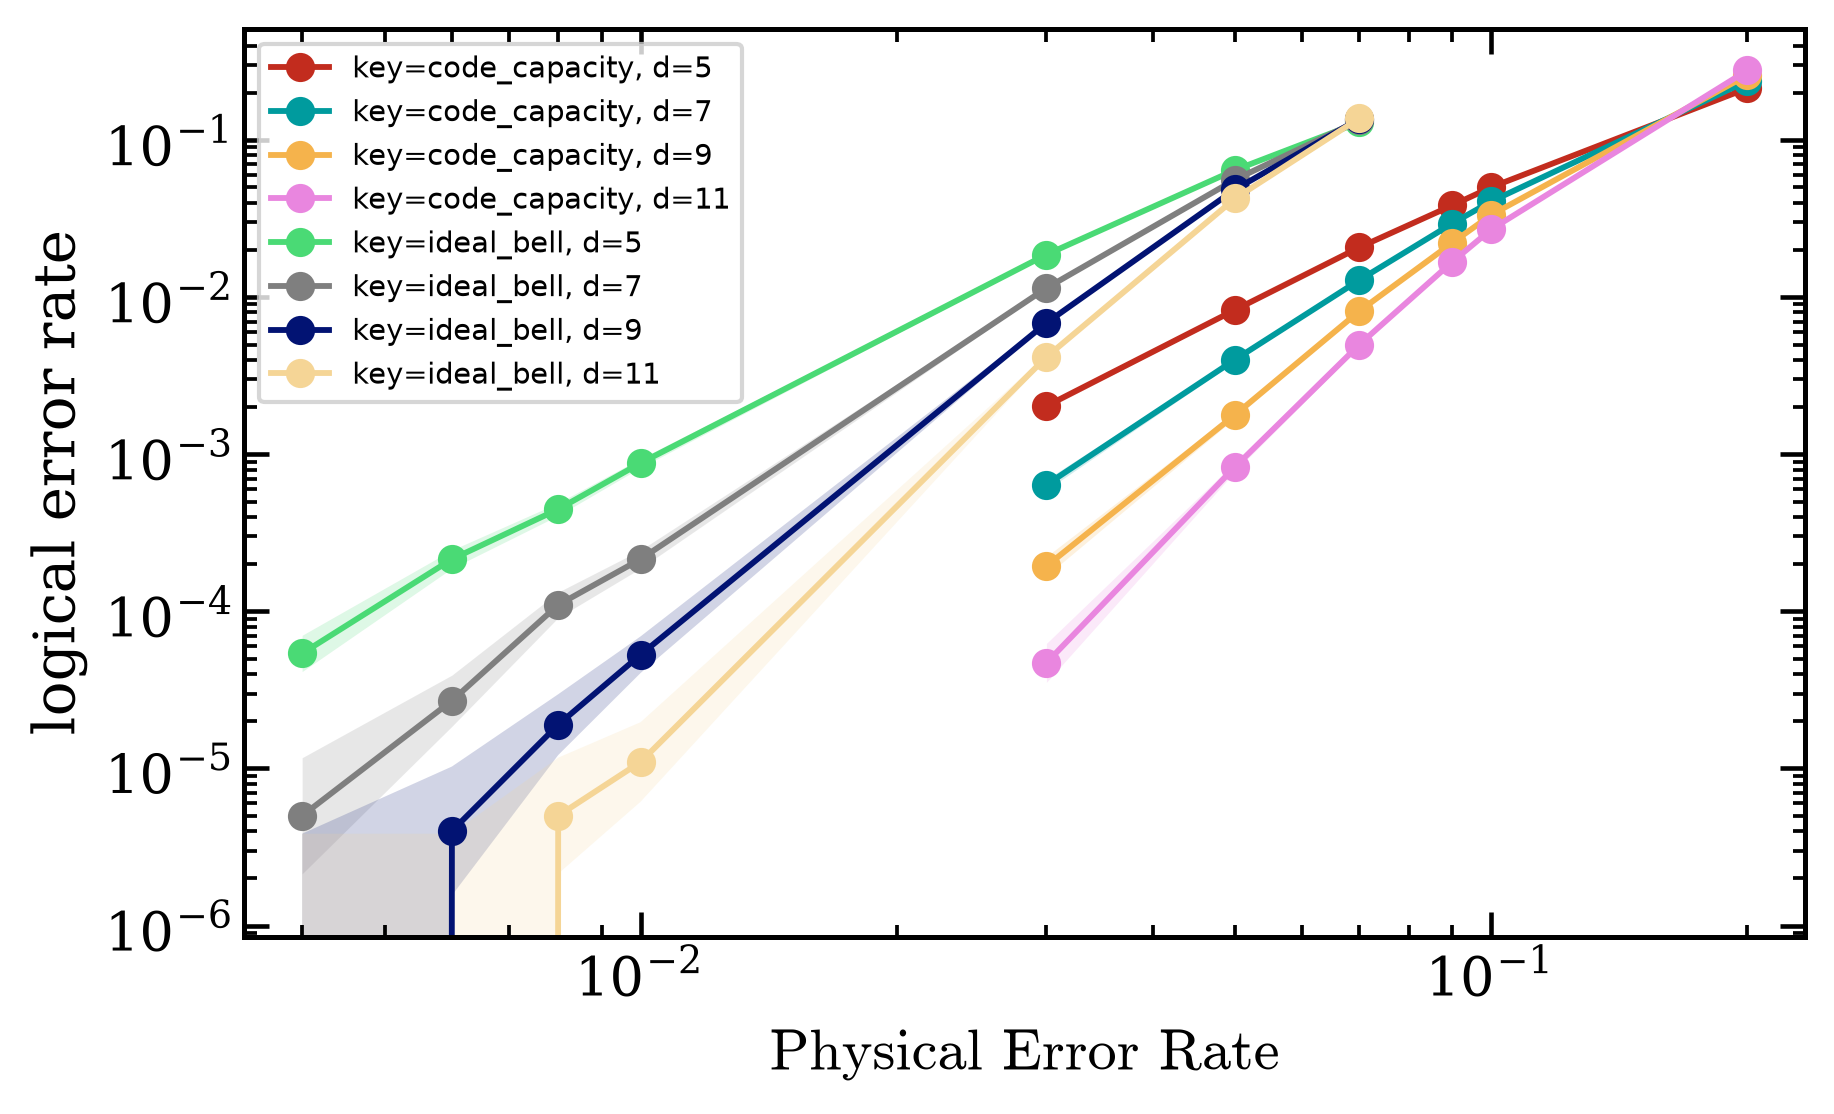

In [13]:
fig, ax = plots.plot_logical_error_rate(
    filter_by={"key": ["code_capacity", "ideal_bell"]},
    group_by=["key", "d"], per_rounds=False,
)
# ax.set_ylim(1e-5, 1)
ax.set_xscale("log")
ax.legend(loc="upper left", fontsize=7)
fig


In [ ]:
fig, ax = plots.plot_logical_error_rate(
    filter_by={"key": ["code_capacity", "ideal_bell"]},
    group_by=["key", "d"],
    per_rounds=False,
    rescale_p_keys=["ideal_bell"],
)
ax.set_xscale("log")
ax.legend(loc="upper left", fontsize=7)
fig

## 2. Stage logical gapのfrequency
`T_idx=1` は最初の段。exact frequency、binなし。


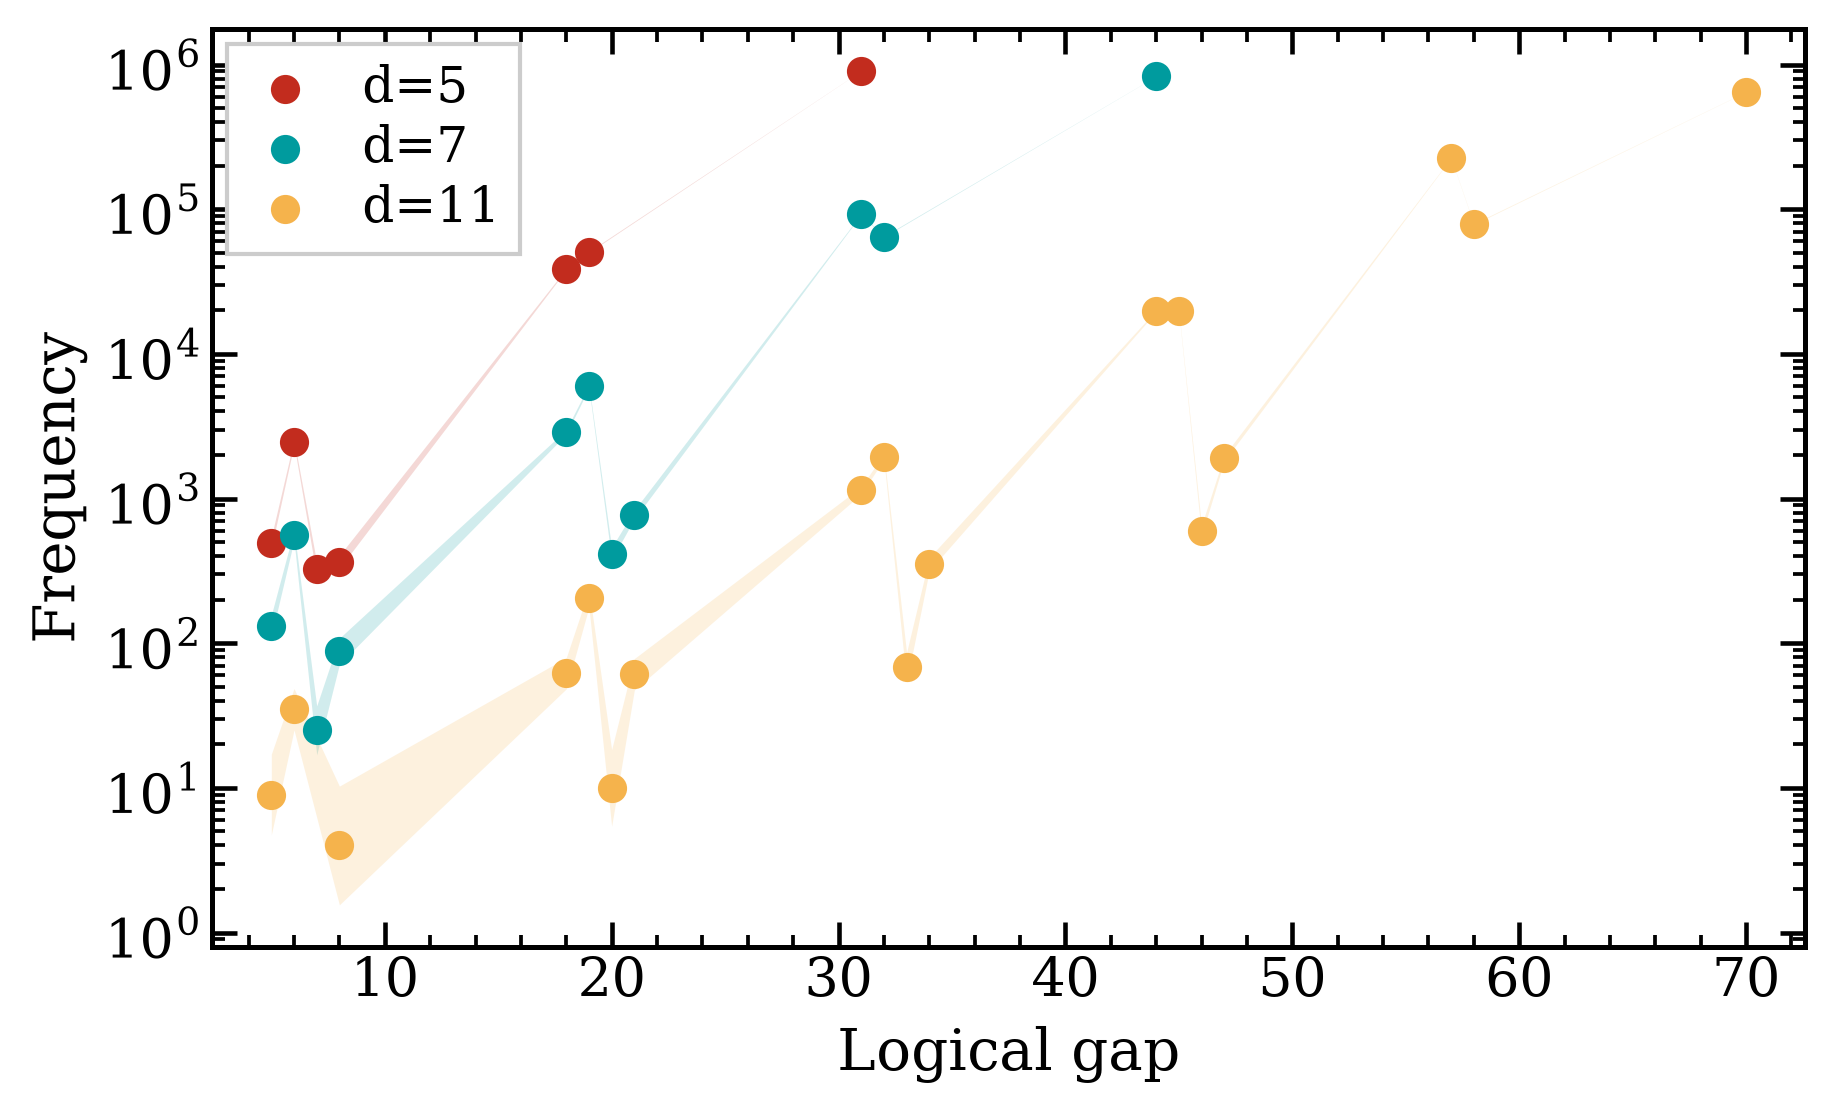

In [4]:
fig, ax, unique_gaps = plots.plot_gap_frequency(
    filter_by={"key": "factory", "p": .001}, group_by="d", T_idx=1, return_unique=True,
)
ax.semilogy()
fig


In [13]:
# groupのtuple -> 判定段(1..T) -> 昇順のunique gapリスト
# unique_gaps[(5,)][1]  # d5の最初の判定だけ取り出す場合
unique_gaps


{(5,): {1: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  2: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  3: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  4: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  5: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  6: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  7: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0],
  8: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 31.0]},
 (7,): {1: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  2: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  3: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  4: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  5: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  6: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  7: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0],
  8: [5.0, 6.0, 7.0, 8.0, 18.0, 19.0, 20.0, 21.0, 31.0, 32.0, 44.0]},
 (11,): {1: [5.0,
   6.0,
   8.0,
   18.0,
   19.0,
   20.0,
   21.0,
   3

## 3. Gap threshold vs abort probability
いずれかの段で **gap <= threshold** なら棄却する。


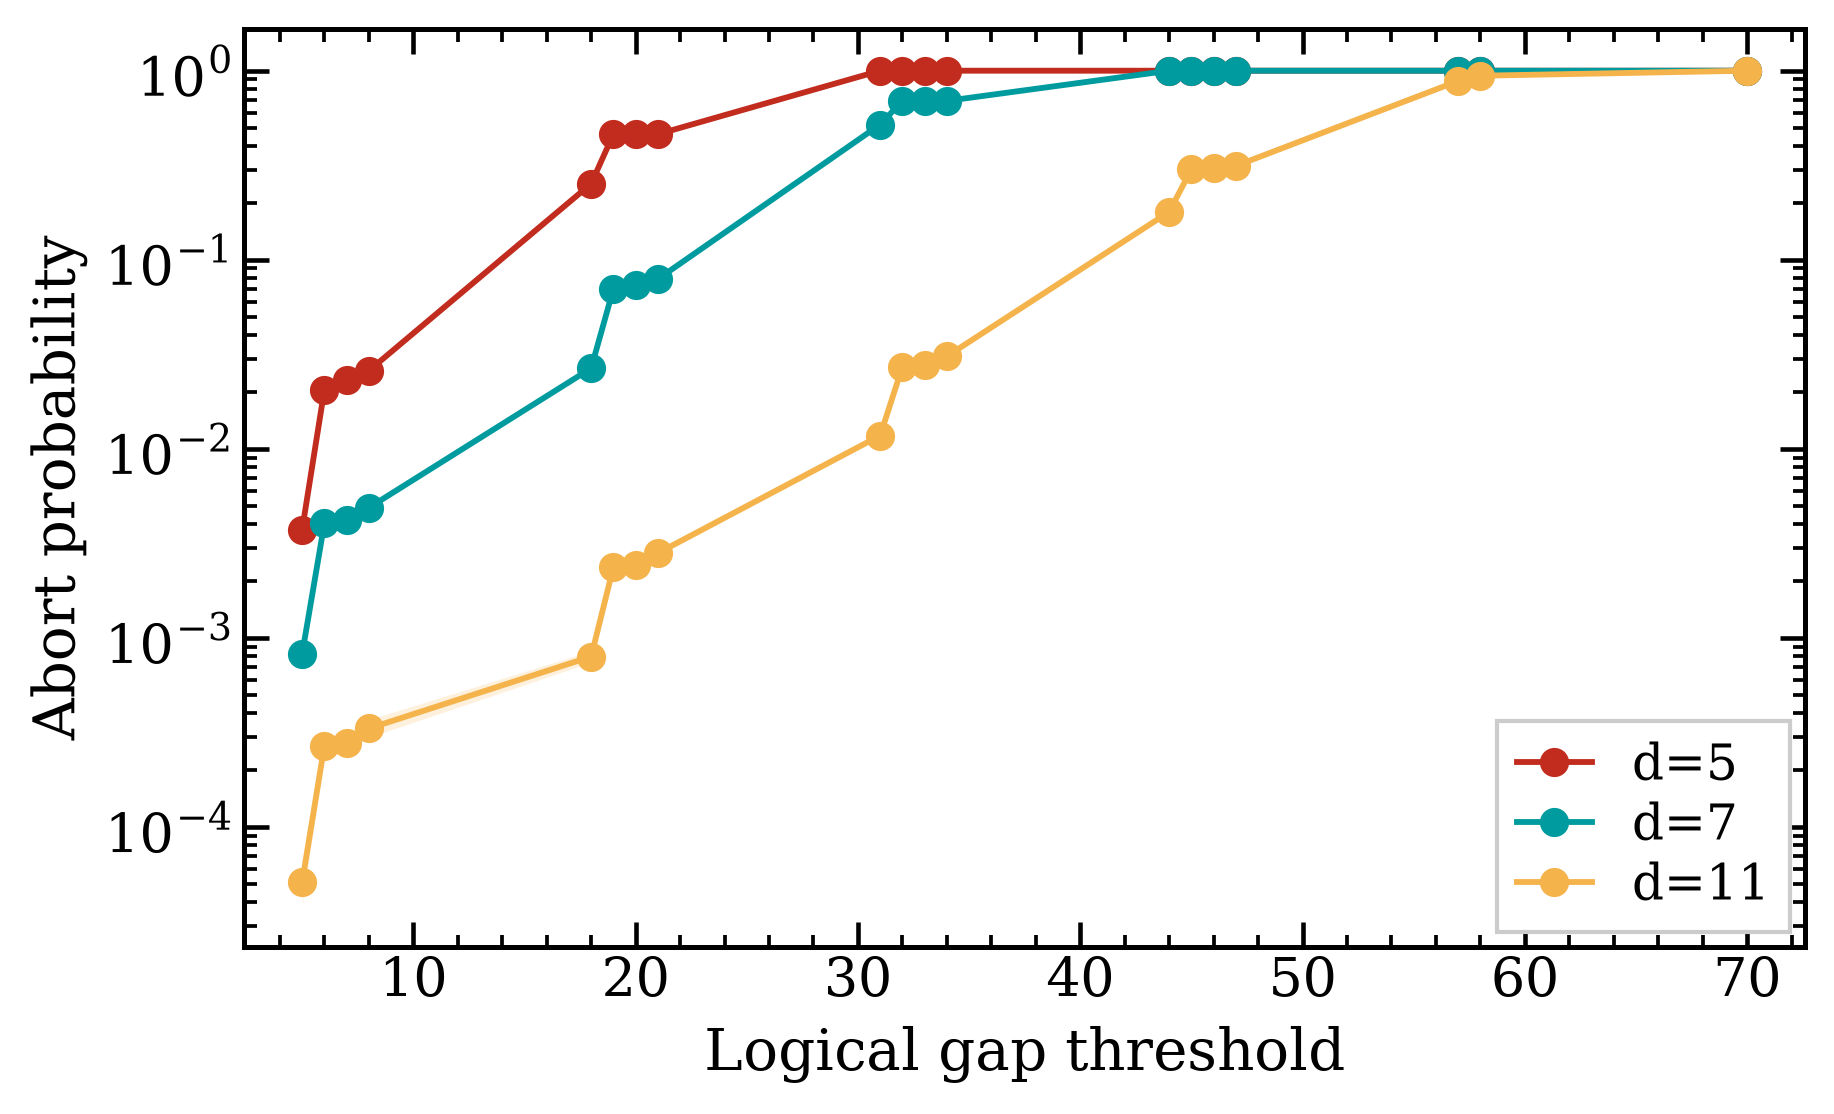

In [7]:
fig, ax = plots.plot_abort(
    filter_by={"key": "factory", "p": .001}, group_by="d",
)
ax.semilogy()
fig


## 4. Gap threshold vs lifetime（積み上げ割合と平均）
左軸: lifetime=0..Tの割合（1本の棒が100%）。色=lifetime、ハッチ=group。
右軸の破線: 棄却shotも含む全shotの平均。Tで打ち切った平均であり、T以降へ外挿しない。
unique閾値が11種類以上なら `gap_threshold` を明示する。


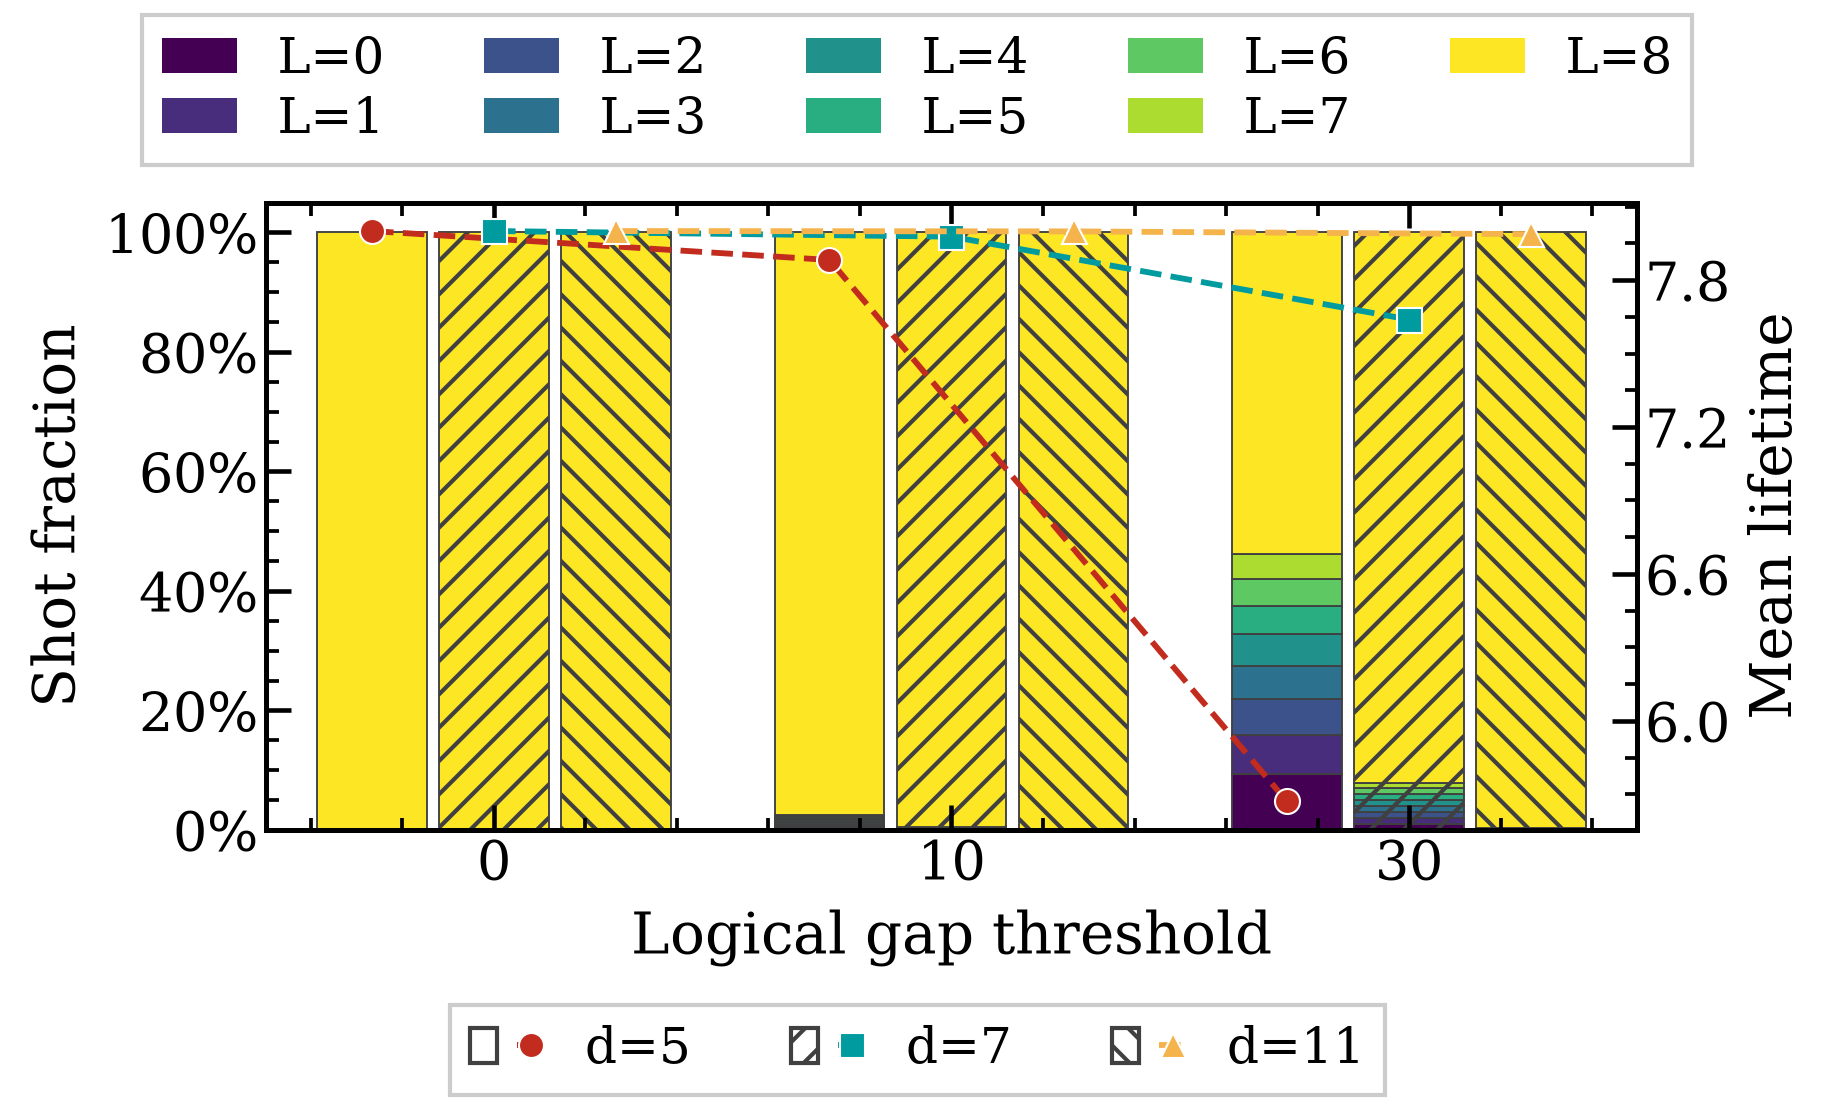

In [6]:
fig, ax, lifetime_summary = plots.plot_lifetime(
    return_summary=True,
    filter_by={"key": "factory", "p": .001}, group_by="d",
    gap_threshold=[0, 10, 30],
)
fig


In [8]:
# groupごとに {threshold: 平均lifetime} を表示
{group: dict(zip(s["thresholds"].tolist(), s["mean_lifetime"].tolist()))
 for group, s in lifetime_summary.items()}


{(5,): {0.0: 8.0, 10.0: 7.881825, 30.0: 5.671086000000001},
 (7,): {0.0: 8.0, 10.0: 7.977105, 30.0: 7.6386829999999994},
 (11,): {0.0: 8.0, 10.0: 7.998529, 30.0: 7.987366}}

## 5. Gap threshold vs LER reduction
`1 - selected_LER / unselected_LER`。負なら悪化。
pまたはdを1値にfilterする。採択ゼロ・baselineエラーゼロは未定義。


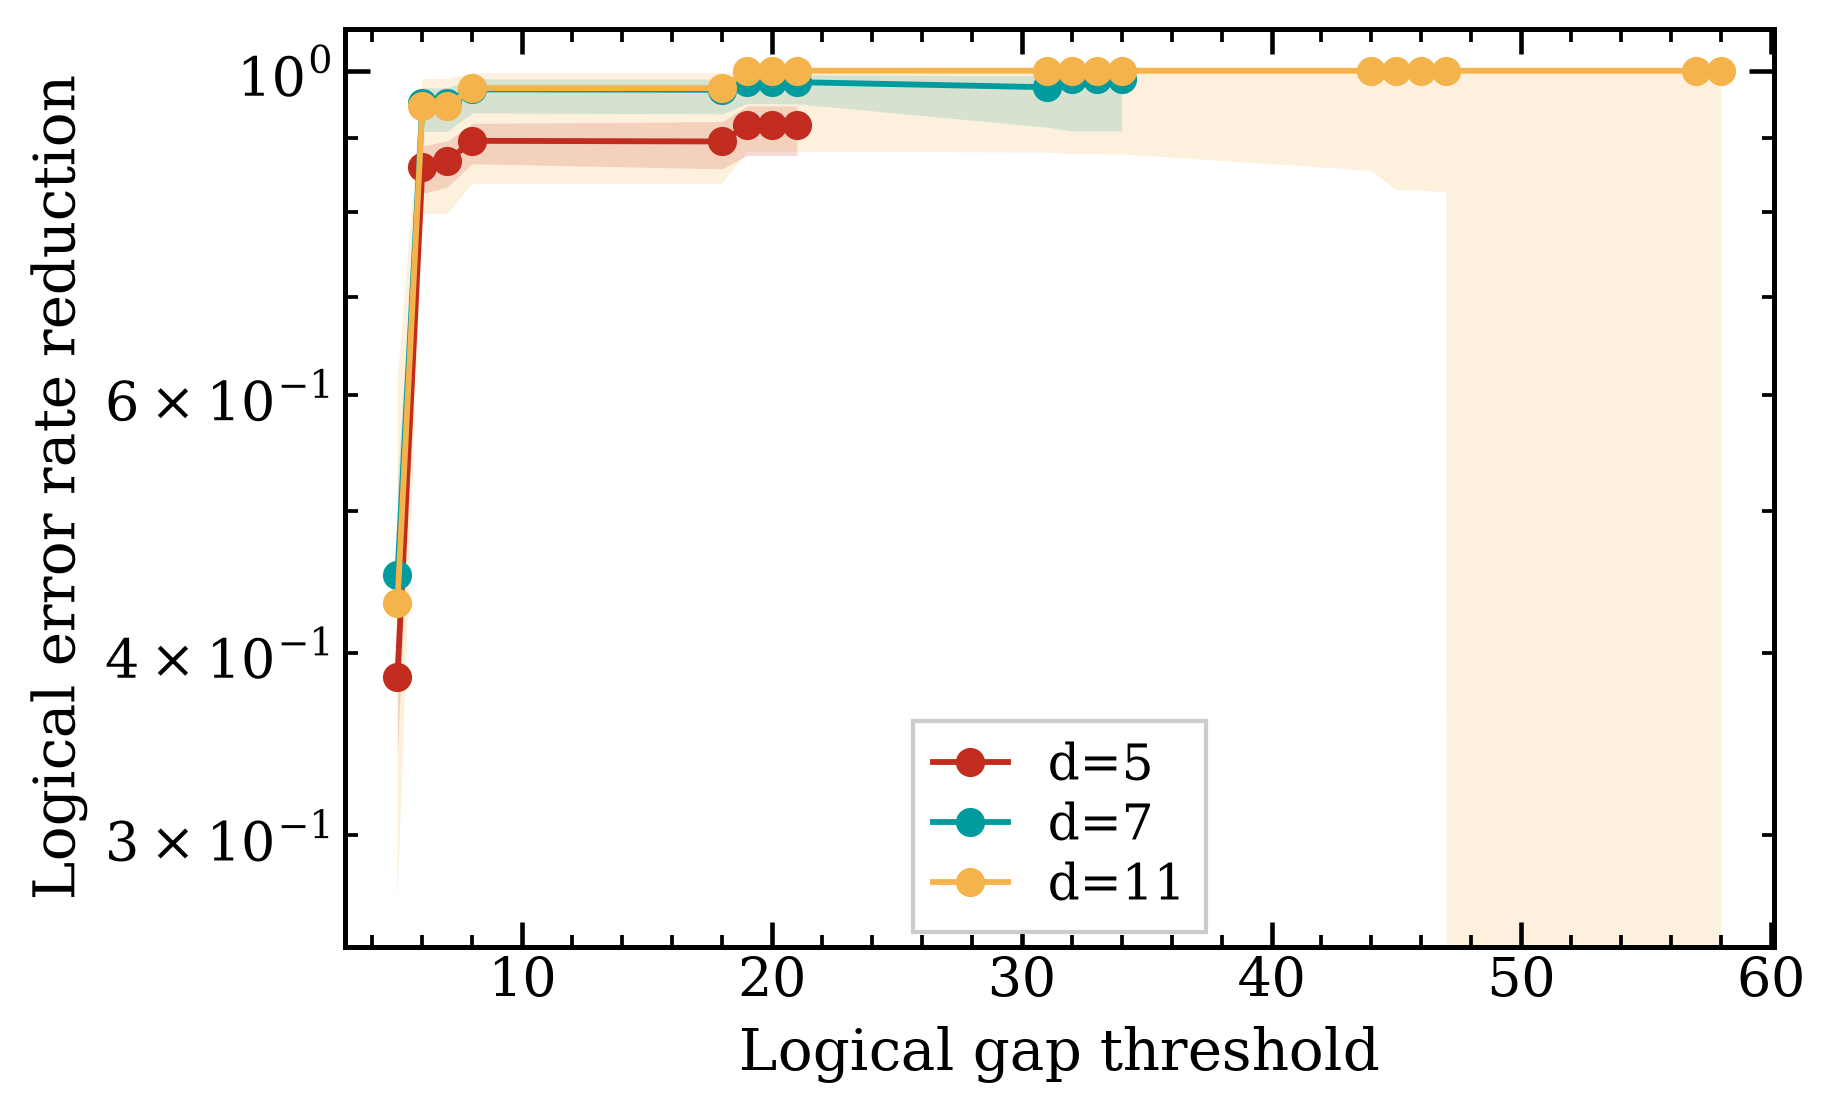

In [11]:
fig, ax = plots.plot_ler_reduction(
    filter_by={"key": "factory", "p": .001}, group_by="d",
)
ax.semilogy()
fig


## 6. 選別後LER vs 物理エラー率
色=d、markerと線種=threshold。per-round換算しない。
factoryのラベルはterminal evaluation oracleのエラーである。


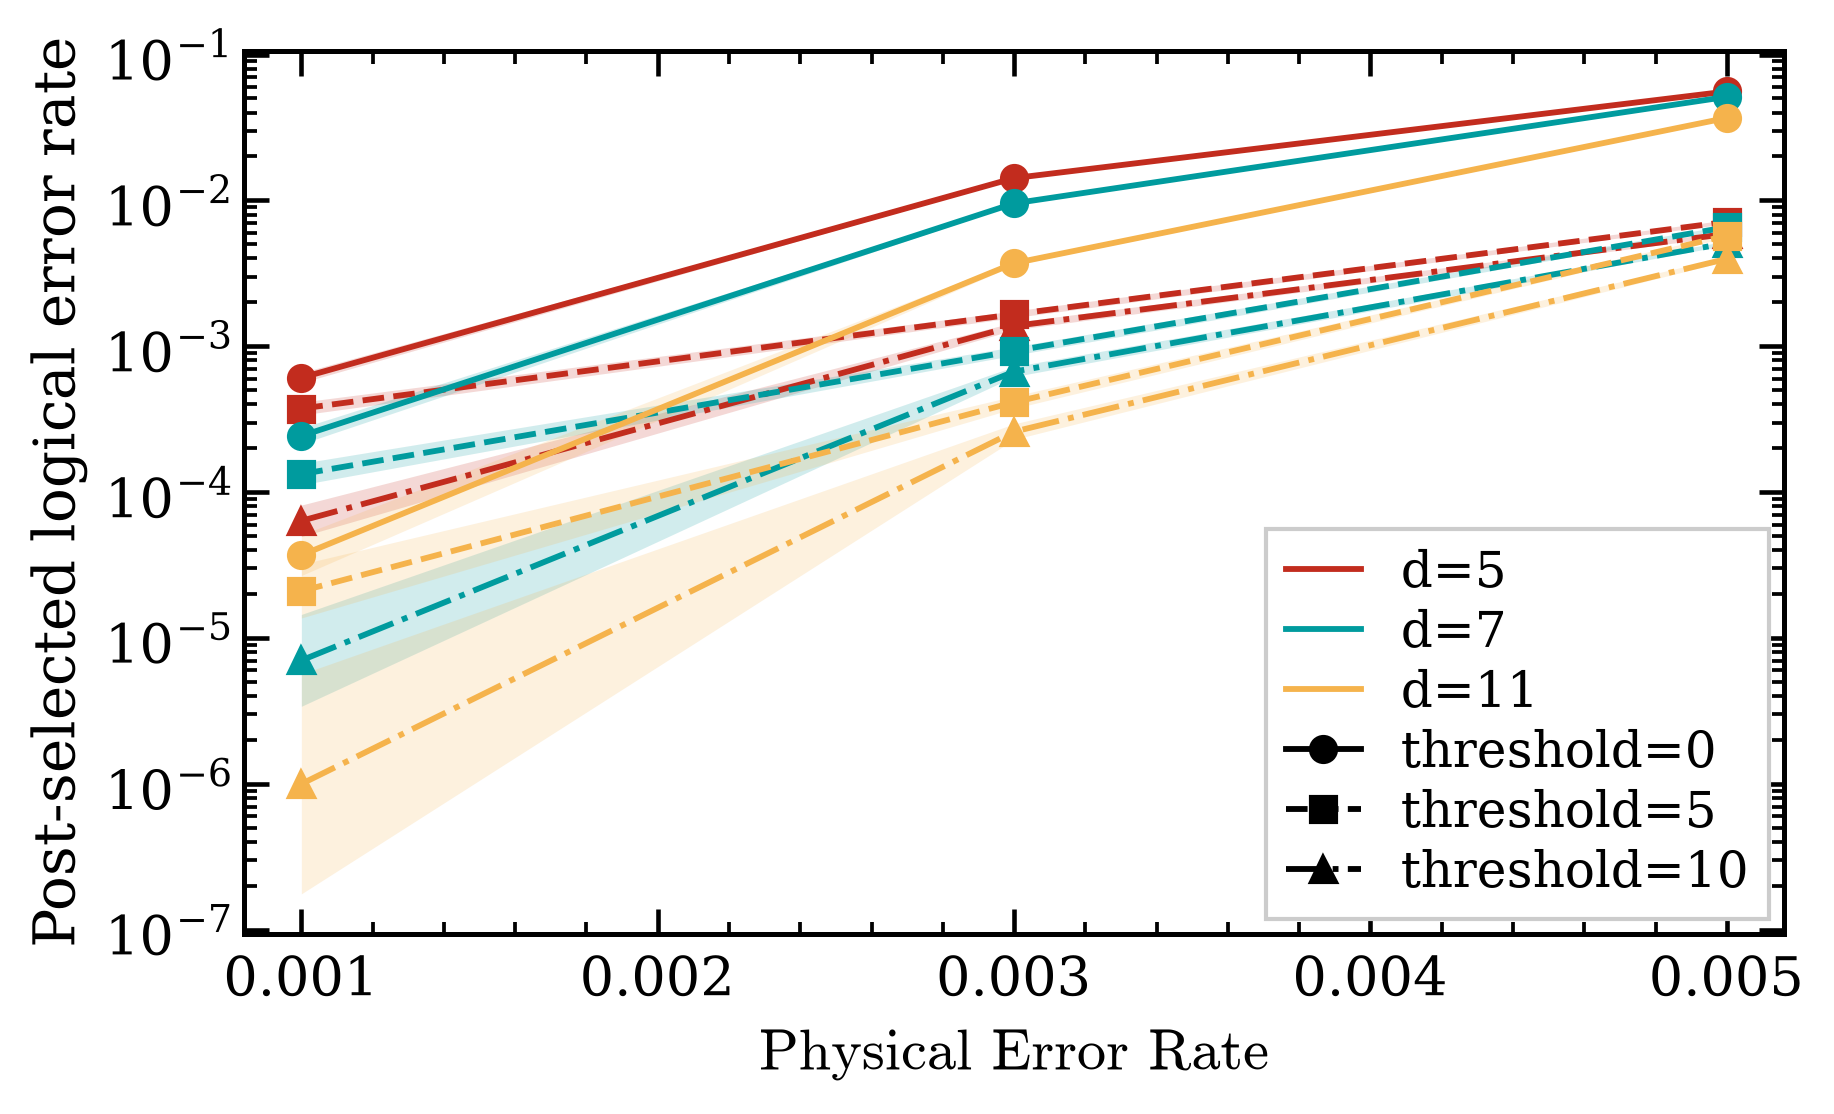

In [13]:
fig, ax = plots.plot_postselected_logical_error_rate(
    filter_by={"key": "factory"}, group_by="d", gap_threshold=[0, 5, 10],
)
fig


## 体裁の調整・保存（任意）
作図は `(fig, ax)` を返す。PDFはベクタ、PNGは300 dpi。
保存先の作成・保存は必要な場合に実行する。


In [9]:
# ax.legend(loc="best", fontsize=7)
# ax.set_ylabel("Post-selected logical error rate")
# output = root.parent / "figures"
# output.mkdir(exist_ok=True)
# style.save(fig, output / "postselected_ler.pdf")
# style.save(fig, output / "postselected_ler.png")
